# Khám phá features và mối liên hệ với sales target

Notebook này giúp xem từng nhóm features đang mang thông tin gì, cách giá trị thay đổi theo ngày dự báo, và chúng liên hệ ra sao với `sales` thật. Phân tích target chỉ dùng labels tuning/validation. Không huấn luyện mô hình trong notebook này.

Một dòng là một cửa hàng–nhóm hàng–ngày dự báo. Lịch sử sales được chốt ở `origin`; target là `sales` của ngày đích. Tương quan chỉ mô tả mức liên hệ trong dữ liệu, không chứng minh tác động nhân quả và không tự quyết định feature nào nên bỏ.

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

_here = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in (_here, *_here.parents)
                     if (p / "data" / "processed" / "features").is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Không tìm thấy data/processed/features; mở notebook trong repo BTLML.")
FEATURE_ROOT = PROJECT_ROOT / "data" / "processed" / "features"
manifest = json.loads((PROJECT_ROOT / "reports" / "features_manifest.json").read_text(encoding="utf-8"))
if not manifest.get("complete"):
    raise ValueError("Manifest features chưa hoàn tất.")
STAGES = ("tuning", "validation", "test")
forecast, labels = {}, {}
for stage in STAGES:
    forecast[stage] = pd.read_parquet(FEATURE_ROOT / stage / "features.parquet")
    label_path = FEATURE_ROOT / stage / "labels.parquet"
    if label_path.is_file():
        labels[stage] = pd.read_parquet(label_path)
print(f"Repo: {PROJECT_ROOT}")
print(f"{len(manifest['feature_columns'])} đầu vào và {len(manifest['metadata_columns'])} metadata; horizon {manifest['horizon_days']} ngày")

Repo: C:\UET\học máy\code\BTLML
43 đầu vào và 3 metadata; horizon 16 ngày


## 1. Ý nghĩa các nhóm features

Bảng này là từ điển ngắn để đọc các cột trước khi xem biểu đồ. `id`, `date`, `origin` dùng nhận diện/đối chiếu; không phải đầu vào mặc định của mô hình.

In [2]:
feature_groups = [
    ("Nhận diện cửa hàng và nhóm hàng", ["store_nbr", "family", "city", "state", "type", "cluster"],
     "Đặc điểm chuỗi và cửa hàng; các mã/nhãn phân loại cần được xử lý như categorical trong model."),
    ("Khuyến mãi", ["onpromotion"],
     "Số mặt hàng đang khuyến mãi ở cửa hàng–nhóm hàng–ngày đích."),
    ("Lịch", ["year", "month", "day", "dayofweek", "is_weekend", "is_payday"],
     "Năm, tháng, ngày, thứ trong tuần, cuối tuần và ngày 15/cuối tháng."),
    ("Ngày lễ và ngày làm việc", ["is_holiday", "is_national_holiday", "is_regional_holiday", "is_local_holiday", "is_transfer_day", "is_bridge_day", "is_additional_day", "is_work_day", "is_event", "is_transferred_original", "is_workday"],
     "Cờ sự kiện theo phạm vi cửa hàng. Ngày lễ gốc được chuyển được đánh dấu riêng, không mặc định là ngày nghỉ thực tế."),
    ("Vị trí trong kỳ dự báo", ["horizon"],
     "Số ngày từ origin đến ngày cần dự báo, từ 1 đến 16."),
    ("Mức sales lịch sử", ["sales_at_origin", "sales_origin_lag_7", "sales_origin_lag_14", "sales_origin_lag_28", "sales_mean_7", "sales_mean_14", "sales_mean_28", "sales_std_7", "sales_std_14", "sales_std_28", "sales_zero_rate_28"],
     "Sales tại origin, lag theo ngày lịch, thống kê mean/std và tỷ lệ sales bằng 0. Cửa sổ thống kê có tính ngày origin; std dùng ddof=0."),
    ("Độ phủ lịch sử", ["sales_observed_days_7", "sales_observed_days_14", "sales_observed_days_28", "sales_at_origin_missing", "sales_origin_lag_7_missing", "sales_origin_lag_14_missing", "sales_origin_lag_28_missing"],
     "Số ngày có nhãn thật trong mỗi cửa sổ và cờ thiếu ở các ngày lag chính xác. Thiếu dữ liệu không được thay bằng sales bằng 0."),
]
feature_dictionary = pd.DataFrame([
    {"nhóm": group, "số cột": len(columns), "các cột": ", ".join(columns), "ý nghĩa": meaning}
    for group, columns, meaning in feature_groups
]).set_index("nhóm")
display(feature_dictionary)
print("Tổng feature theo từ điển:", sum(len(cols) for _, cols, _ in feature_groups))
print("Feature trong manifest:", len(manifest["feature_columns"]))

,số cột,các cột,ý nghĩa
nhóm,,,
Nhận diện cửa hàng và nhóm hàng,6,"store_nbr, family, city, state, type, cluster",Đặc điểm chuỗi và cửa hàng; các mã/nhãn phân l...
Khuyến mãi,1,onpromotion,Số mặt hàng đang khuyến mãi ở cửa hàng–nhóm hà...
Lịch,6,"year, month, day, dayofweek, is_weekend, is_pa...","Năm, tháng, ngày, thứ trong tuần, cuối tuần và..."
Ngày lễ và ngày làm việc,11,"is_holiday, is_national_holiday, is_regional_h...",Cờ sự kiện theo phạm vi cửa hàng. Ngày lễ gốc ...
Vị trí trong kỳ dự báo,1,horizon,"Số ngày từ origin đến ngày cần dự báo, từ 1 đế..."
Mức sales lịch sử,11,"sales_at_origin, sales_origin_lag_7, sales_ori...","Sales tại origin, lag theo ngày lịch, thống kê..."
Độ phủ lịch sử,7,"sales_observed_days_7, sales_observed_days_14,...",Số ngày có nhãn thật trong mỗi cửa sổ và cờ th...


Tổng feature theo từ điển: 43
Feature trong manifest: 43


## 2. Xem ví dụ một chuỗi qua 16 ngày dự báo

Bảng sau cho thấy các covariates theo từng ngày đích, target thật của validation và lịch sử tại origin. Các cột lịch sử phải không đổi trong 16 ngày cùng một origin; lịch, khuyến mãi và `horizon` có thể đổi theo ngày.

,id,date,origin,horizon,store_nbr,family,onpromotion,dayofweek,is_weekend,is_holiday,sales_at_origin,sales_origin_lag_7,sales_mean_7,sales_mean_28,sales_zero_rate_28,sales
0,2972376,2017-07-31,2017-07-30,1,1,AUTOMOTIVE,0,0,False,False,1.0,0.0,4.714286,4.571429,0.071429,8.0
1,2974158,2017-08-01,2017-07-30,2,1,AUTOMOTIVE,0,1,False,False,1.0,0.0,4.714286,4.571429,0.071429,5.0
2,2975940,2017-08-02,2017-07-30,3,1,AUTOMOTIVE,0,2,False,False,1.0,0.0,4.714286,4.571429,0.071429,4.0
3,2977722,2017-08-03,2017-07-30,4,1,AUTOMOTIVE,0,3,False,False,1.0,0.0,4.714286,4.571429,0.071429,3.0
4,2979504,2017-08-04,2017-07-30,5,1,AUTOMOTIVE,0,4,False,False,1.0,0.0,4.714286,4.571429,0.071429,8.0
5,2981286,2017-08-05,2017-07-30,6,1,AUTOMOTIVE,0,5,True,False,1.0,0.0,4.714286,4.571429,0.071429,5.0
6,2983068,2017-08-06,2017-07-30,7,1,AUTOMOTIVE,0,6,True,False,1.0,0.0,4.714286,4.571429,0.071429,6.0
7,2984850,2017-08-07,2017-07-30,8,1,AUTOMOTIVE,0,0,False,False,1.0,0.0,4.714286,4.571429,0.071429,7.0
8,2986632,2017-08-08,2017-07-30,9,1,AUTOMOTIVE,0,1,False,False,1.0,0.0,4.714286,4.571429,0.071429,4.0
9,2988414,2017-08-09,2017-07-30,10,1,AUTOMOTIVE,0,2,False,False,1.0,0.0,4.714286,4.571429,0.071429,7.0


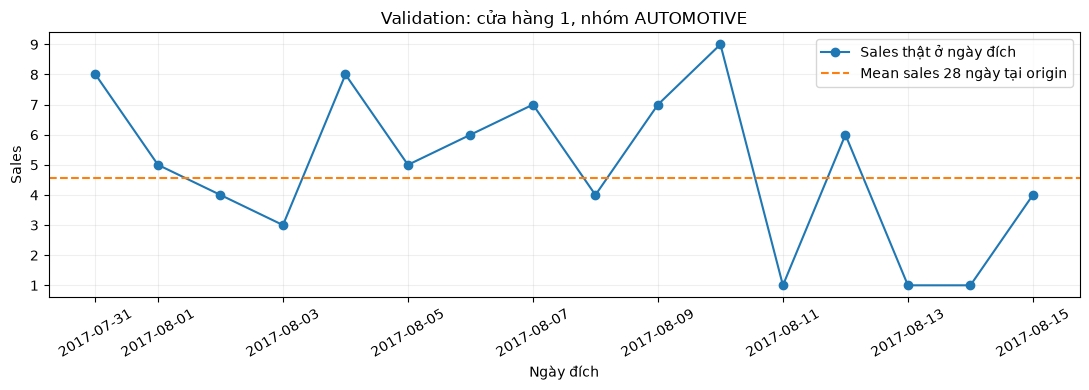

In [3]:
validation = forecast["validation"]
example_store = validation["store_nbr"].iloc[0]
example_family = validation["family"].iloc[0]
example = validation.loc[
    validation["store_nbr"].eq(example_store) & validation["family"].eq(example_family)
].sort_values("date").copy()
example = example.merge(labels["validation"], on="id", how="left", validate="one_to_one")
show_cols = ["id", "date", "origin", "horizon", "store_nbr", "family", "onpromotion",
             "dayofweek", "is_weekend", "is_holiday", "sales_at_origin",
             "sales_origin_lag_7", "sales_mean_7", "sales_mean_28", "sales_zero_rate_28", "sales"]
display(example[show_cols].reset_index(drop=True))

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(example["date"], example["sales"], marker="o", label="Sales thật ở ngày đích")
ax.axhline(example["sales_mean_28"].iloc[0], linestyle="--", color="tab:orange", label="Mean sales 28 ngày tại origin")
ax.set(title=f"Validation: cửa hàng {example_store}, nhóm {example_family}", xlabel="Ngày đích", ylabel="Sales")
ax.legend(); ax.grid(alpha=.2)
plt.xticks(rotation=30); plt.tight_layout()

## 3. Phân bố và độ thiếu của các features

Sales thường lệch phải. Biểu đồ dùng `log1p` để dễ nhìn phần lớn quan sát mà không xóa các giá trị lớn. Cờ thiếu/độ phủ được đọc riêng để phân biệt ngày không quan sát với sales bằng 0.

,tuning,validation,test
store_nbr,0.00%,0.00%,0.00%
family,0.00%,0.00%,0.00%
onpromotion,0.00%,0.00%,0.00%
city,0.00%,0.00%,0.00%
state,0.00%,0.00%,0.00%
type,0.00%,0.00%,0.00%
cluster,0.00%,0.00%,0.00%
year,0.00%,0.00%,0.00%
month,0.00%,0.00%,0.00%
day,0.00%,0.00%,0.00%


,count,mean,std,min,10%,50%,90%,max
sales_at_origin,28512.0,630.613,1764.130,0.0,0.000,36.000,1567.000,18340.000
sales_origin_lag_7,28512.0,574.797,1612.914,0.0,0.000,35.000,1388.762,15686.000
sales_origin_lag_14,28512.0,617.735,1734.432,0.0,0.000,36.000,1550.011,17417.000
sales_origin_lag_28,28512.0,727.486,2071.211,0.0,0.000,43.638,1769.000,21180.000
sales_mean_7,28512.0,474.732,1244.205,0.0,0.286,30.214,1274.830,11326.714
sales_mean_14,28512.0,467.619,1231.872,0.0,0.214,29.893,1250.700,11317.929
sales_mean_28,28512.0,473.419,1248.196,0.0,0.286,30.804,1282.179,11334.893
sales_std_7,28512.0,129.306,350.221,0.0,0.452,11.500,340.852,4219.230
sales_std_14,28512.0,122.419,318.624,0.0,0.495,11.674,340.502,3532.261
sales_std_28,28512.0,126.814,329.353,0.0,0.549,12.287,337.304,3588.469


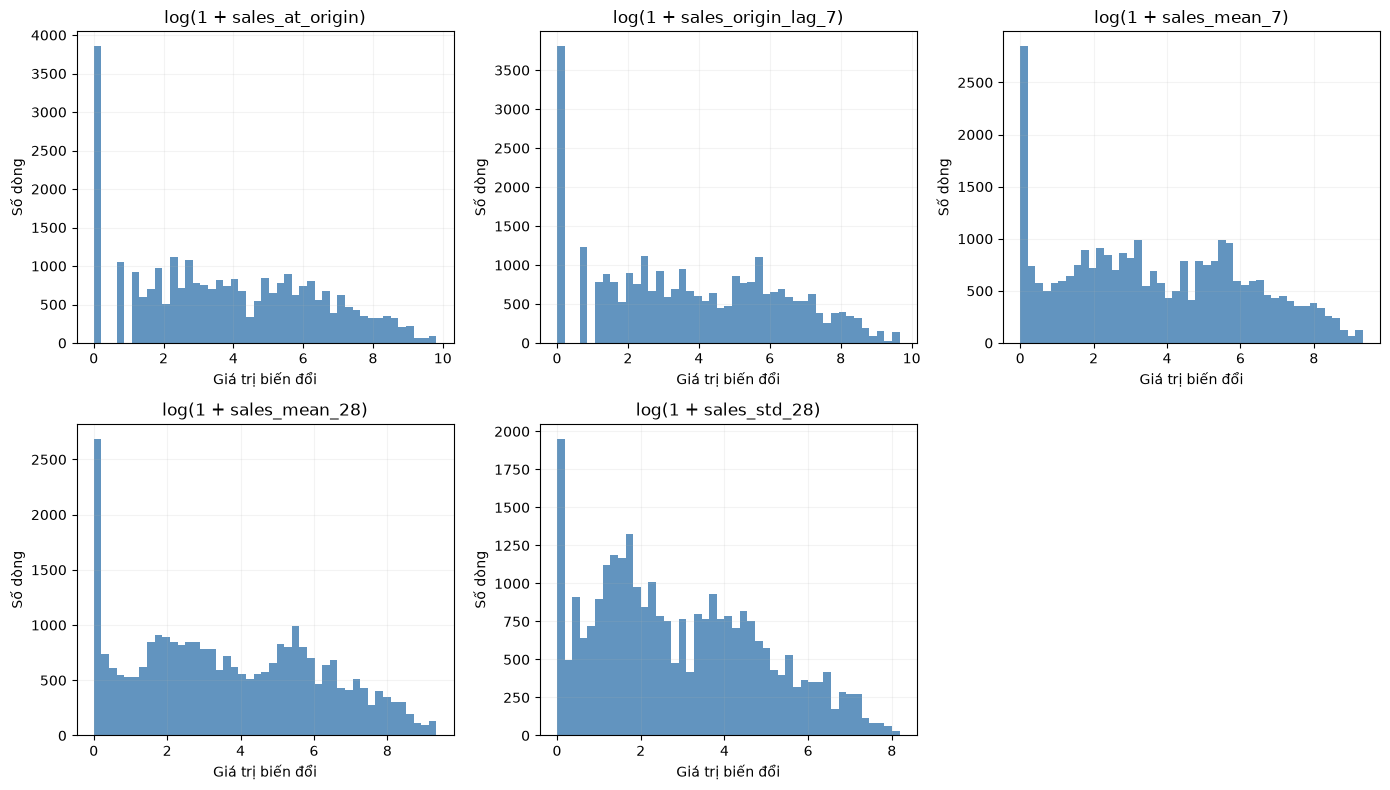

In [4]:
history_cols = manifest["history_columns"]
missing = pd.DataFrame({stage: forecast[stage][manifest["feature_columns"]].isna().mean()
                        for stage in STAGES})
display(missing.style.format("{:.2%}"))

plot_cols = ["sales_at_origin", "sales_origin_lag_7", "sales_mean_7", "sales_mean_28", "sales_std_28"]
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, col in zip(axes.flat, plot_cols):
    values = validation[col].dropna()
    ax.hist(np.log1p(values.clip(lower=0)), bins=45, color="steelblue", alpha=.85)
    ax.set(title=f"log(1 + {col})", xlabel="Giá trị biến đổi", ylabel="Số dòng")
    ax.grid(alpha=.15)
axes.flat[-1].axis("off")
plt.tight_layout()

display(validation[history_cols].describe(percentiles=[.1, .5, .9]).T.round(3))

## 4. Đặc trưng khác nhau giữa nhóm hàng

Các nhóm hàng có quy mô và mức sales lịch sử khác nhau. Bảng/biểu đồ dưới đây xếp nhóm hàng theo `sales_mean_28` trong validation. Đây là trung bình trên các cửa hàng–ngày của nhóm hàng.

,rows,mean_sales_28,median_sales_28,zero_rate_28,promotion_items
family,,,,,
GROCERY I,864,4517.14,3981.18,0.00,48.06
BEVERAGES,864,3597.82,3163.04,0.00,19.06
PRODUCE,864,2351.28,1640.83,0.00,28.70
CLEANING,864,1320.54,1153.75,0.00,15.94
DAIRY,864,870.81,709.75,0.00,21.59
BREAD/BAKERY,864,539.91,529.89,0.00,10.60
POULTRY,864,391.61,246.06,0.00,3.59
MEATS,864,375.71,270.13,0.00,4.09
HOME CARE,864,320.85,271.52,0.00,6.77


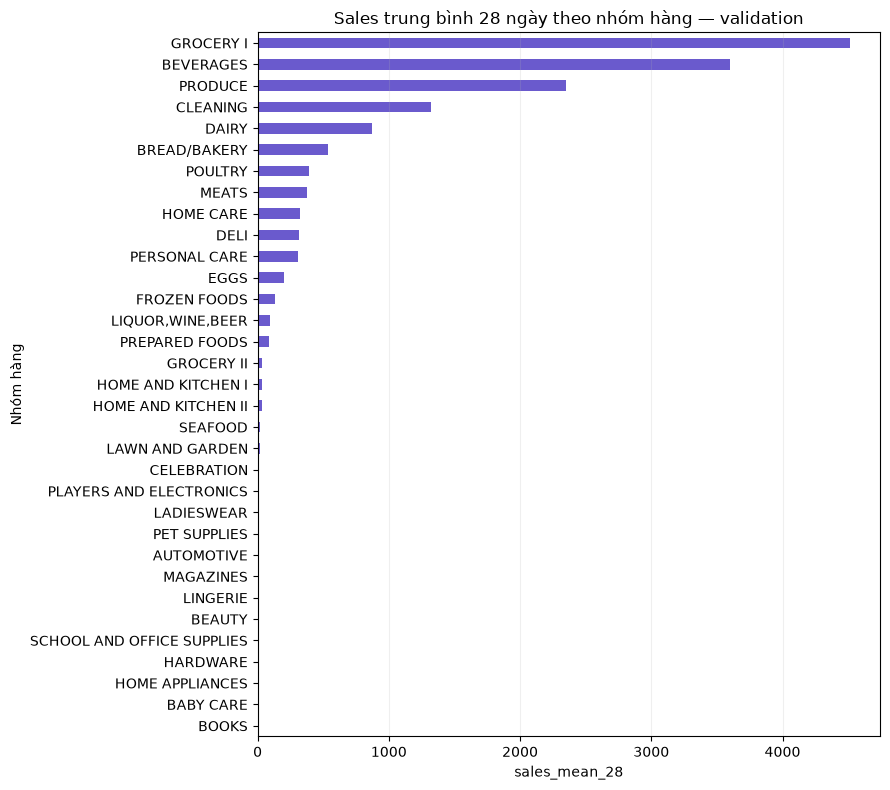

In [5]:
family_profile = validation.groupby("family", observed=True).agg(
    rows=("id", "size"),
    mean_sales_28=("sales_mean_28", "mean"),
    median_sales_28=("sales_mean_28", "median"),
    zero_rate_28=("sales_zero_rate_28", "mean"),
    promotion_items=("onpromotion", "mean"),
).sort_values("mean_sales_28", ascending=False)
display(family_profile.round(2))
ax = family_profile["mean_sales_28"].sort_values().plot.barh(figsize=(9, 8), color="slateblue")
ax.set(title="Sales trung bình 28 ngày theo nhóm hàng — validation", xlabel="sales_mean_28", ylabel="Nhóm hàng")
ax.grid(axis="x", alpha=.2); plt.tight_layout()

## 5. Features lịch và khuyến mãi theo horizon

So sánh tỷ lệ dòng có khuyến mãi, ngày lễ và cuối tuần theo từng ngày dự báo. `onpromotion` là số mặt hàng khuyến mãi, còn các cột `is_*` là cờ Boolean. Những biến này được biết tại ngày đích theo dữ liệu cuộc thi.

,rows,promotion_rows,promotion_items_mean,holiday_rows,weekend_rows,promotion_fraction,holiday_fraction,weekend_fraction
horizon,,,,,,,,
1,1782,697,4.854,0,0,0.391,0.000,0.0
2,1782,703,5.696,0,0,0.395,0.000,0.0
3,1782,755,9.273,0,0,0.424,0.000,0.0
4,1782,760,4.410,0,0,0.426,0.000,0.0
5,1782,867,7.965,0,0,0.487,0.000,0.0
6,1782,784,4.873,33,1782,0.440,0.019,1.0
7,1782,779,5.368,0,1782,0.437,0.000,1.0
8,1782,719,4.607,0,0,0.403,0.000,0.0
9,1782,756,5.970,0,0,0.424,0.000,0.0


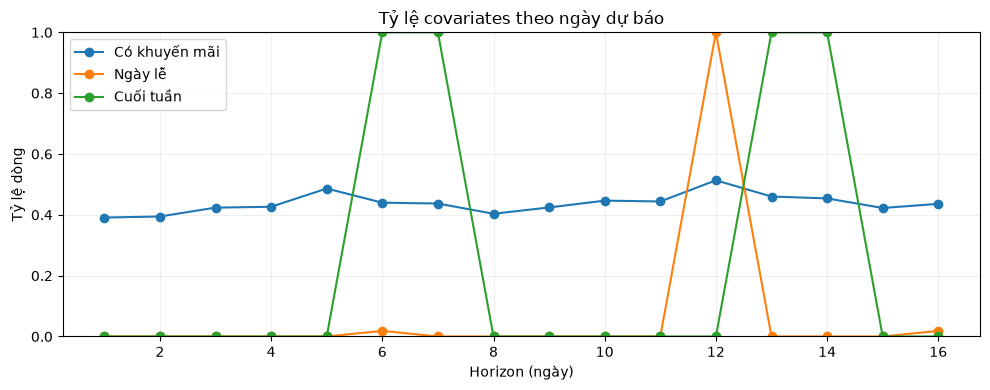

In [6]:
profile = validation.groupby("horizon", observed=True).agg(
    rows=("id", "size"),
    promotion_rows=("onpromotion", lambda s: int(s.gt(0).sum())),
    promotion_items_mean=("onpromotion", "mean"),
    holiday_rows=("is_holiday", "sum"),
    weekend_rows=("is_weekend", "sum"),
)
profile["promotion_fraction"] = profile["promotion_rows"] / profile["rows"]
profile["holiday_fraction"] = profile["holiday_rows"] / profile["rows"]
profile["weekend_fraction"] = profile["weekend_rows"] / profile["rows"]
display(profile.round(3))
fig, ax = plt.subplots(figsize=(10, 4))
for col, label in [("promotion_fraction", "Có khuyến mãi"), ("holiday_fraction", "Ngày lễ"), ("weekend_fraction", "Cuối tuần")]:
    ax.plot(profile.index, profile[col], marker="o", label=label)
ax.set(title="Tỷ lệ covariates theo ngày dự báo", xlabel="Horizon (ngày)", ylabel="Tỷ lệ dòng", ylim=(0, 1))
ax.legend(); ax.grid(alpha=.2); plt.tight_layout()

## 6. Liên hệ giữa features số và sales target

Tính tương quan Spearman trên tuning và validation riêng biệt. Spearman đo xu hướng đơn điệu và ít nhạy với độ lệch của sales hơn Pearson. Mã cửa hàng, nhóm hàng và ngày lịch dạng mã không đưa vào phép tính như số liên tục. Hệ số gần 0 không loại trừ quan hệ phi tuyến hoặc tương tác.

tuning


,Spearman rho,Pearson r
sales_mean_28,0.981,0.959
sales_mean_14,0.981,0.959
sales_mean_7,0.981,0.958
sales_origin_lag_7,0.971,0.944
sales_at_origin,0.971,0.940
sales_std_14,0.969,0.907
sales_origin_lag_14,0.969,0.948
sales_std_28,0.969,0.909
sales_origin_lag_28,0.967,0.943
sales_std_7,0.965,0.875


validation


,Spearman rho,Pearson r
sales_mean_14,0.976,0.967
sales_mean_28,0.976,0.967
sales_mean_7,0.976,0.967
sales_at_origin,0.967,0.947
sales_std_28,0.966,0.898
sales_origin_lag_7,0.964,0.947
sales_std_14,0.964,0.899
sales_origin_lag_14,0.963,0.947
sales_origin_lag_28,0.962,0.950
sales_std_7,0.960,0.891


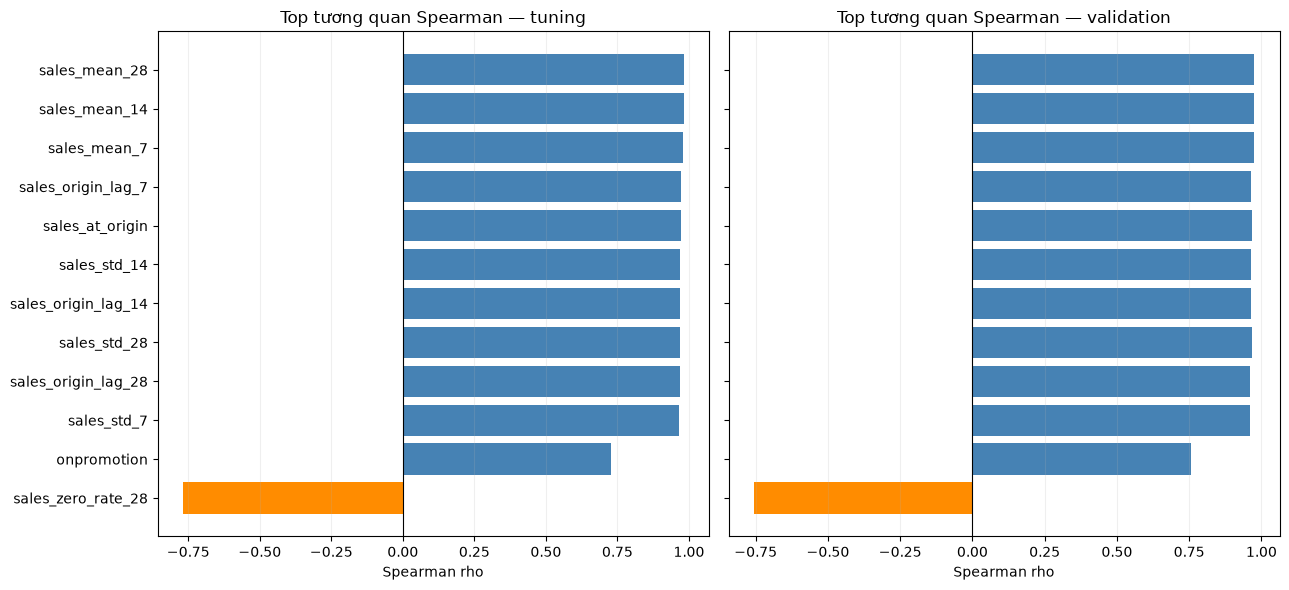

In [7]:
correlation_candidates = [
    "horizon", "onpromotion",
    "sales_at_origin", "sales_origin_lag_7", "sales_origin_lag_14", "sales_origin_lag_28",
    "sales_mean_7", "sales_mean_14", "sales_mean_28",
    "sales_std_7", "sales_std_14", "sales_std_28", "sales_zero_rate_28",
    "sales_observed_days_7", "sales_observed_days_14", "sales_observed_days_28",
    "sales_at_origin_missing", "sales_origin_lag_7_missing",
    "sales_origin_lag_14_missing", "sales_origin_lag_28_missing",
]
correlation_tables = {}
for stage in ("tuning", "validation"):
    view = forecast[stage][["id", *correlation_candidates]].merge(
        labels[stage], on="id", validate="one_to_one")
    usable = [col for col in correlation_candidates if view[col].nunique(dropna=True) > 1]
    spearman = view[usable + ["sales"]].corr(method="spearman", numeric_only=True)["sales"].drop("sales")
    pearson = view[usable + ["sales"]].corr(method="pearson", numeric_only=True)["sales"].drop("sales")
    table = pd.DataFrame({"Spearman rho": spearman, "Pearson r": pearson})
    table["abs Spearman"] = table["Spearman rho"].abs()
    correlation_tables[stage] = table.sort_values("abs Spearman", ascending=False)
    print(stage)
    display(correlation_tables[stage].drop(columns="abs Spearman").round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharey=True)
for ax, stage in zip(axes, ("tuning", "validation")):
    selected = correlation_tables[stage].head(12).sort_values("Spearman rho")
    ax.barh(selected.index, selected["Spearman rho"], color=np.where(selected["Spearman rho"] >= 0, "steelblue", "darkorange"))
    ax.axvline(0, color="black", linewidth=.8)
    ax.set(title=f"Top tương quan Spearman — {stage}", xlabel="Spearman rho")
    ax.grid(axis="x", alpha=.2)
plt.tight_layout()

## 7. Xem quan hệ mục tiêu bằng biểu đồ và nhóm

Biểu đồ hexbin cho thấy mật độ quan sát giữa lịch sử 28 ngày và sales thật ở validation. Bảng còn lại so sánh target theo mức khuyến mãi và theo nhóm hàng. Sales lớn ở một nhóm không đồng nghĩa feature nhóm hàng tự nó gây ra khác biệt; cửa hàng, ngày và mức khuyến mãi cũng có thể liên quan.

,rows,sales_mean,sales_median,zero_fraction
promotion_group,,,,
0,16031,55.099,6.000,0.259
1–5,5050,155.198,61.000,0.000
6+,7431,1568.044,683.422,0.000


,rows,sales_mean,sales_median,zero_fraction
family,,,,
GROCERY I,864,4606.96,3878.94,0.00
BEVERAGES,864,3478.48,2946.50,0.00
PRODUCE,864,2288.75,1609.85,0.00
CLEANING,864,1232.92,1040.00,0.00
DAIRY,864,834.53,690.00,0.00
BREAD/BAKERY,864,540.27,487.66,0.00
POULTRY,864,374.49,233.13,0.00
MEATS,864,371.61,258.61,0.00
PERSONAL CARE,864,321.33,267.00,0.00


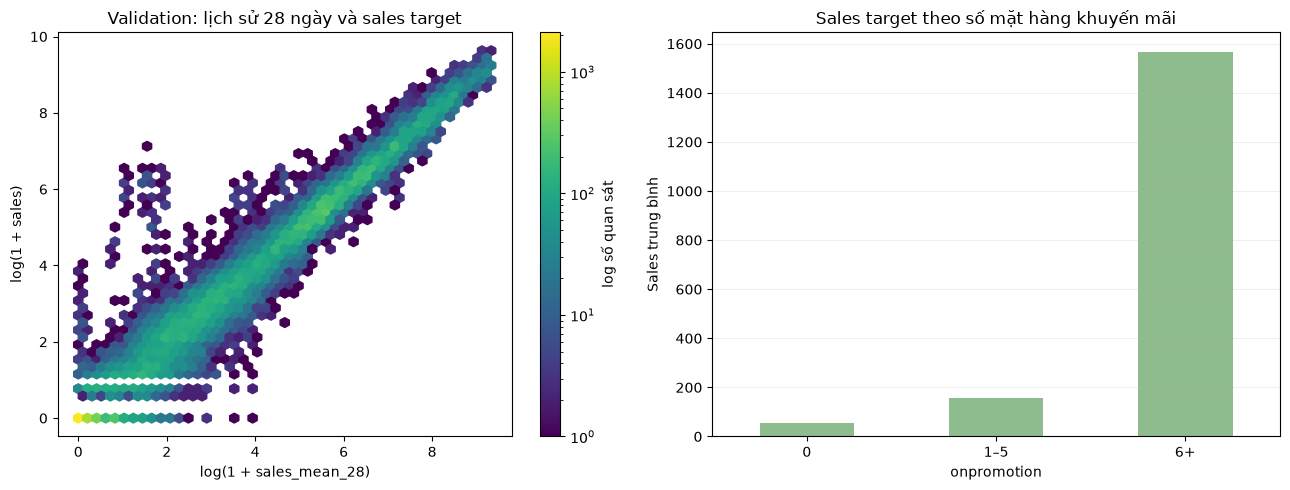

In [8]:
target_view = forecast["validation"].merge(labels["validation"], on="id", validate="one_to_one")
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
hexes = axes[0].hexbin(np.log1p(target_view["sales_mean_28"]), np.log1p(target_view["sales"]),
                       gridsize=45, bins="log", mincnt=1, cmap="viridis")
axes[0].set(title="Validation: lịch sử 28 ngày và sales target", xlabel="log(1 + sales_mean_28)", ylabel="log(1 + sales)")
fig.colorbar(hexes, ax=axes[0], label="log số quan sát")

promo_bins = pd.cut(target_view["onpromotion"], bins=[-1, 0, 5, np.inf], labels=["0", "1–5", "6+"])
promo_target = target_view.assign(promotion_group=promo_bins).groupby("promotion_group", observed=True).agg(
    rows=("sales", "size"), sales_mean=("sales", "mean"), sales_median=("sales", "median"),
    zero_fraction=("sales", lambda s: s.eq(0).mean()))
display(promo_target.round(3))
promo_target["sales_mean"].plot.bar(ax=axes[1], color="darkseagreen")
axes[1].set(title="Sales target theo số mặt hàng khuyến mãi", xlabel="onpromotion", ylabel="Sales trung bình")
axes[1].tick_params(axis="x", rotation=0); axes[1].grid(axis="y", alpha=.2)
plt.tight_layout()

target_by_family = target_view.groupby("family", observed=True).agg(
    rows=("sales", "size"), sales_mean=("sales", "mean"), sales_median=("sales", "median"),
    zero_fraction=("sales", lambda s: s.eq(0).mean()))
display(target_by_family.sort_values("sales_mean", ascending=False).round(2))

## 8. Đọc kết quả để chuẩn bị huấn luyện

- Dùng `tuning/train.parquet` cho thử nghiệm và chọn biến; đánh giá sau khi chốt cấu hình trên `validation`.
- Dùng `test/train.parquet` để fit mô hình cuối cùng và `test/features.parquet` để dự báo. Test không có target.
- Đưa vào model các cột từ `manifest["feature_columns"]`. Không dùng `id`, `date`, `origin` làm đầu vào mặc định; giữ `id` để nối dự báo với submission.
- Mã hóa `family`, `city`, `state`, `type`; cân nhắc xử lý `store_nbr` và `cluster` như categorical thay vì biến liên tục.
- Features lịch sử có thể lệch và có scale khác nhau. Nếu dùng biến đổi như `log1p`, imputation hoặc scaling, chỉ fit tham số trên train của stage tương ứng.
- Tương quan chỉ là bước khám phá. Quyết định giữ/bỏ biến dựa trên kiểm định thời gian và hiệu năng mô hình, không dựa duy nhất vào correlation trên validation.
- Notebook mô tả associations trong dữ liệu; không suy ra tác động nhân quả từ `onpromotion`, ngày lễ hay đặc trưng cửa hàng.